In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("E:/python/vs_code/Water_Consumption_Analysis/data/water_consumption.csv")

df.head()

,Date,Zone,Population,Temperature_C,Precipitation_mm,Day_of_Week,Water_Consumption_m3
0,2024-01-01,Zone_1,45000,3.49,7.47,Monday,4731.53
1,2024-01-01,Zone_2,60000,3.49,7.47,Monday,7167.17
2,2024-01-01,Zone_3,35000,3.49,7.47,Monday,4166.90
3,2024-01-01,Zone_4,50000,3.49,7.47,Monday,6318.45
4,2024-01-02,Zone_1,45000,0.26,5.38,Tuesday,5387.78


In [3]:
df.shape

(2924, 7)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2924 entries, 0 to 2923
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Date                  2924 non-null   object 
 1   Zone                  2924 non-null   object 
 2   Population            2924 non-null   int64  
 3   Temperature_C         2924 non-null   float64
 4   Precipitation_mm      2924 non-null   float64
 5   Day_of_Week           2924 non-null   object 
 6   Water_Consumption_m3  2924 non-null   float64
dtypes: float64(3), int64(1), object(3)
memory usage: 160.0+ KB


In [5]:
df.describe()

,Population,Temperature_C,Precipitation_mm,Water_Consumption_m3
count,2924.000000,2924.000000,2924.000000,2924.000000
mean,47500.000000,14.833324,5.206977,5781.087035
std,9015.419945,10.003860,5.932497,1281.873299
min,35000.000000,-6.500000,0.000000,2943.580000
25%,42500.000000,7.020000,1.010000,4793.740000
50%,47500.000000,14.250000,2.910000,5687.960000
75%,52500.000000,22.130000,7.470000,6677.842500
max,60000.000000,37.940000,39.520000,10082.780000


In [6]:
df.isnull().sum()

Date                    0
Zone                    0
Population              0
Temperature_C           0
Precipitation_mm        0
Day_of_Week             0
Water_Consumption_m3    0
dtype: int64

In [7]:
df.duplicated().sum()

0

In [8]:
df.dtypes

Date                     object
Zone                     object
Population                int64
Temperature_C           float64
Precipitation_mm        float64
Day_of_Week              object
Water_Consumption_m3    float64
dtype: object

In [9]:
#define date as Date
df["Date"] = pd.to_datetime(df["Date"])

In [10]:
#define year , month , month name , season
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Month_Name"] = df["Date"].dt.month_name()
df["Season"] = df["Month"].map({
    12: "Winter",
    1: "Winter",
    2: "Winter",
    3: "Spring",
    4: "Spring",
    5: "Spring",
    6: "Summer",
    7: "Summer",
    8: "Summer",
    9: "Autumn",
    10: "Autumn",
    11: "Autumn"
})

In [11]:
#define Per Capita Consumption
df["Per_Capita_Consumption"] = (
    df["Water_Consumption_m3"] / df["Population"]
)

#define Per Capita Consumption ---> litr
df["Per_Capita_Liters"] = (
    df["Per_Capita_Consumption"] * 1000
)

In [12]:
df.head()

,Date,Zone,Population,Temperature_C,Precipitation_mm,Day_of_Week,Water_Consumption_m3,Year,Month,Month_Name,Season,Per_Capita_Consumption,Per_Capita_Liters
0,2024-01-01,Zone_1,45000,3.49,7.47,Monday,4731.53,2024,1,January,Winter,0.105145,105.145111
1,2024-01-01,Zone_2,60000,3.49,7.47,Monday,7167.17,2024,1,January,Winter,0.119453,119.452833
2,2024-01-01,Zone_3,35000,3.49,7.47,Monday,4166.90,2024,1,January,Winter,0.119054,119.054286
3,2024-01-01,Zone_4,50000,3.49,7.47,Monday,6318.45,2024,1,January,Winter,0.126369,126.369000
4,2024-01-02,Zone_1,45000,0.26,5.38,Tuesday,5387.78,2024,1,January,Winter,0.119728,119.728444


In [13]:
df[
    [
        "Zone",
        "Population",
        "Water_Consumption_m3",
        "Per_Capita_Liters"
    ]
].head(10)

,Zone,Population,Water_Consumption_m3,Per_Capita_Liters
0,Zone_1,45000,4731.53,105.145111
1,Zone_2,60000,7167.17,119.452833
2,Zone_3,35000,4166.90,119.054286
3,Zone_4,50000,6318.45,126.369000
4,Zone_1,45000,5387.78,119.728444
5,Zone_2,60000,5890.56,98.176000
6,Zone_3,35000,3502.09,100.059714
7,Zone_4,50000,5584.30,111.686000
8,Zone_1,45000,4846.55,107.701111
9,Zone_2,60000,5600.30,93.338333


In [14]:
#مجموع مصرف هر منطقه
zone_consumption = (
    df.groupby("Zone")["Water_Consumption_m3"]
    .sum()
    .sort_values(ascending=False)
)

zone_consumption

Zone
Zone_2    5342335.37
Zone_4    4450717.32
Zone_1    3973866.44
Zone_3    3136979.36
Name: Water_Consumption_m3, dtype: float64

In [15]:
#میانگین مصرف سرانه هر منطقه
zone_per_capita = (
    df.groupby("Zone")["Per_Capita_Liters"]
    .mean()
    .sort_values(ascending=False)
)

zone_per_capita

Zone
Zone_3    122.610098
Zone_2    121.804272
Zone_4    121.770652
Zone_1    120.804573
Name: Per_Capita_Liters, dtype: float64

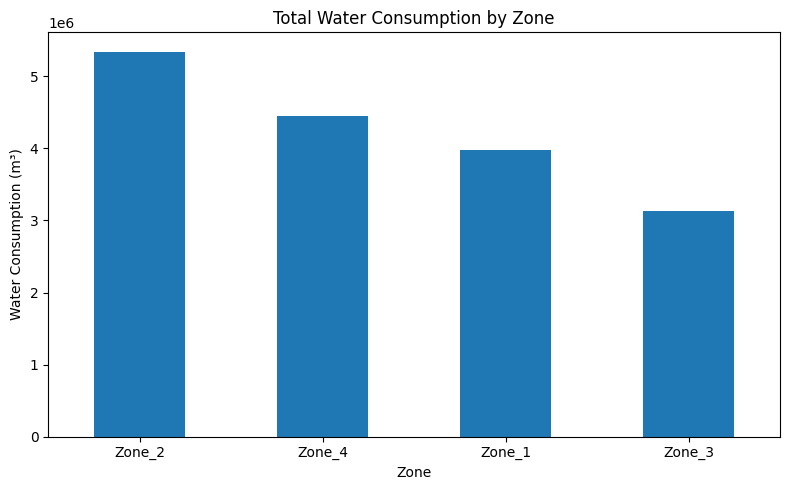

In [16]:
#کدام منطقه در مجموع آب بیشتری مصرف کرده است.
plt.figure(figsize=(8, 5))

zone_consumption.plot(kind="bar")

plt.title("Total Water Consumption by Zone")
plt.xlabel("Zone")
plt.ylabel("Water Consumption (m³)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

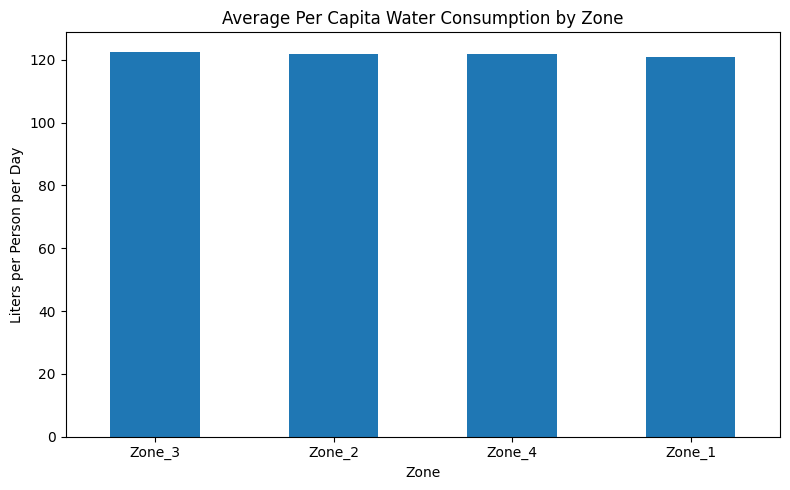

In [17]:
#ساکنان کدام منطقه به‌طور متوسط مصرف سرانه بیشتری دارند.
plt.figure(figsize=(8, 5))

zone_per_capita.plot(kind="bar")

plt.title("Average Per Capita Water Consumption by Zone")
plt.xlabel("Zone")
plt.ylabel("Liters per Person per Day")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [18]:
print(zone_per_capita.round(2))

Zone
Zone_3    122.61
Zone_2    121.80
Zone_4    121.77
Zone_1    120.80
Name: Per_Capita_Liters, dtype: float64


In [19]:
#تأثیر دما بر مصرف آب
#1-محاسبه ضریب همبستگی با NumPy
correlation = np.corrcoef(
    df["Temperature_C"],
    df["Water_Consumption_m3"]
)[0, 1]

print(f"Correlation: {correlation:.3f}")

Correlation: 0.288


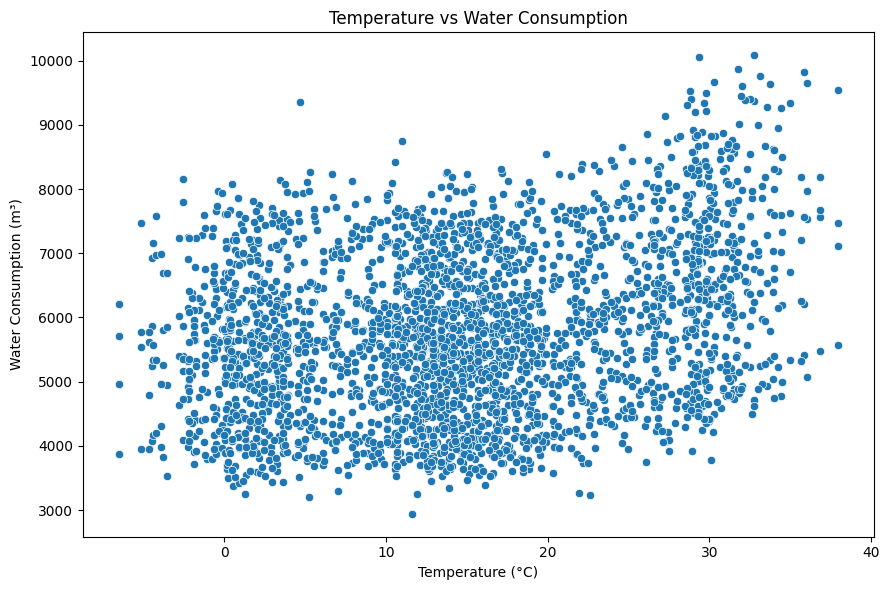

In [20]:
#حالا رابطه را به صورت تصویری ببینیم:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Temperature_C",
    y="Water_Consumption_m3"
)

plt.title("Temperature vs Water Consumption")
plt.xlabel("Temperature (°C)")
plt.ylabel("Water Consumption (m³)")

plt.tight_layout()
plt.show()

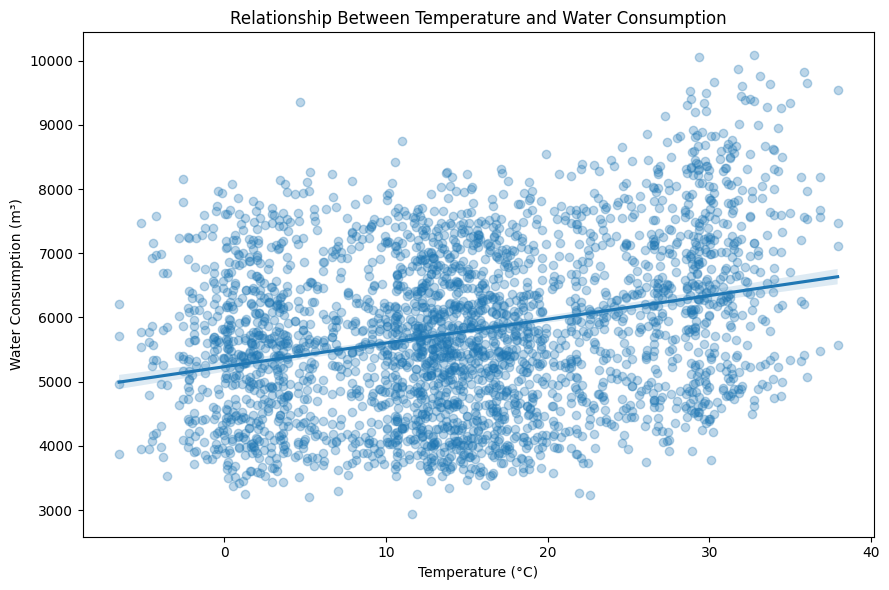

In [21]:
#Seaborn می‌تواند خط روند هم به ما نشان دهد:
plt.figure(figsize=(9, 6))

sns.regplot(
    data=df,
    x="Temperature_C",
    y="Water_Consumption_m3",
    scatter_kws={"alpha": 0.3}
)

plt.title("Relationship Between Temperature and Water Consumption")
plt.xlabel("Temperature (°C)")
plt.ylabel("Water Consumption (m³)")

plt.tight_layout()
plt.show()

In [22]:
#مصرف آب در فصل‌های مختلف
#به جای مجموع مصرف، میانگین مصرف روزانه را برای هر فصل محاسبه می‌کنیم.
season_consumption = (
    df.groupby("Season")["Water_Consumption_m3"]
    .mean()
    .sort_values(ascending=False)
)

season_consumption

Season
Summer    6459.746916
Spring    5591.573098
Autumn    5584.534135
Winter    5481.472528
Name: Water_Consumption_m3, dtype: float64

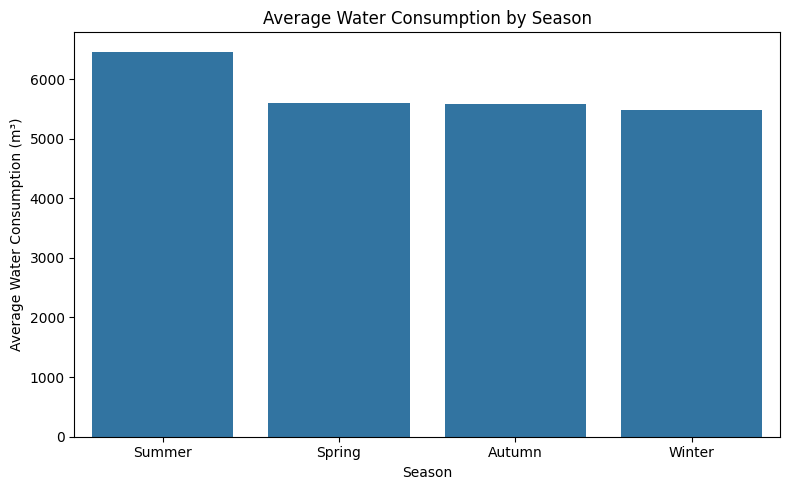

In [23]:
#به جای مجموع مصرف، میانگین مصرف روزانه را برای هر فصل محاسبه می‌کنیم.
plt.figure(figsize=(8, 5))

sns.barplot(
    x=season_consumption.index,
    y=season_consumption.values
)

plt.title("Average Water Consumption by Season")
plt.xlabel("Season")
plt.ylabel("Average Water Consumption (m³)")

plt.tight_layout()
plt.show()

In [24]:
#Correlation در هر فصل
season_correlation = (
    df.groupby("Season")
    .apply(
        lambda group: group["Temperature_C"]
        .corr(group["Water_Consumption_m3"])
    )
)

print(season_correlation.round(3))

Season
Autumn    0.026
Spring    0.026
Summer    0.259
Winter    0.011
dtype: float64


In [25]:
#میانگین مصرف هر ماه:
monthly_consumption = (
    df.groupby("Month")["Water_Consumption_m3"]
    .mean()
)

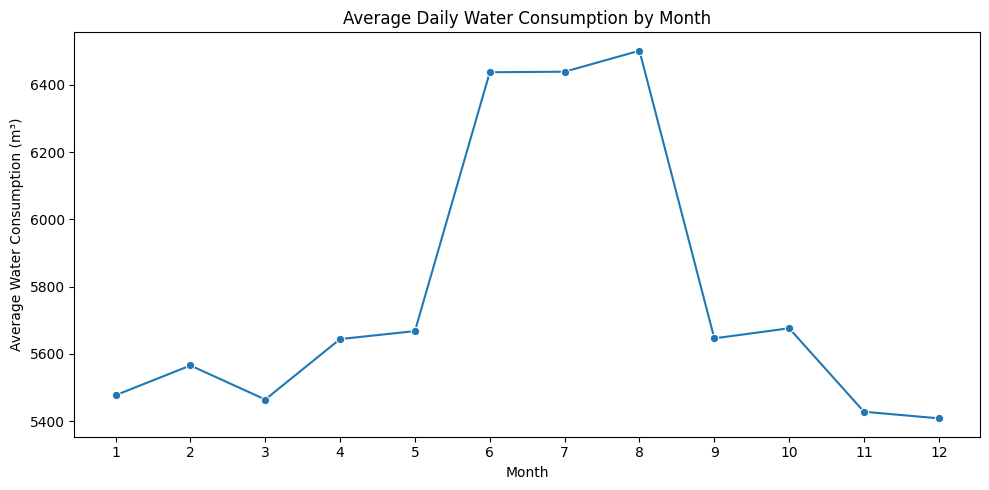

In [26]:
#نمودار مصرف آب را در طول سال
plt.figure(figsize=(10, 5))

sns.lineplot(
    x=monthly_consumption.index,
    y=monthly_consumption.values,
    marker="o"
)

plt.title("Average Daily Water Consumption by Month")
plt.xlabel("Month")
plt.ylabel("Average Water Consumption (m³)")
plt.xticks(range(1, 13))

plt.tight_layout()
plt.show()

In [27]:
#پیدا کردن مصرف‌های غیرعادی
#1-اول میانگین و انحراف معیار مصرف را حساب میکنیم:
mean_consumption = df["Water_Consumption_m3"].mean()
std_consumption = df["Water_Consumption_m3"].std()

print("Mean:", mean_consumption)
print("Std:", std_consumption)

Mean: 5781.087034883722
Std: 1281.8732986687978


In [28]:
#حالا Z-score را بسازیم
df["Z_Score"] = (
    (df["Water_Consumption_m3"] - mean_consumption)
    / std_consumption
)

In [29]:
#بعد روزهای غیرعادی را پیدا کنیم:
anomalies = df[
    df["Z_Score"].abs() > 2
]

anomalies.head(10)

,Date,Zone,Population,Temperature_C,Precipitation_mm,Day_of_Week,Water_Consumption_m3,Year,Month,Month_Name,Season,Per_Capita_Consumption,Per_Capita_Liters,Z_Score
125,2024-02-01,Zone_2,60000,4.72,5.01,Thursday,9361.30,2024,2,February,Winter,0.156022,156.021667,2.792954
485,2024-05-01,Zone_2,60000,19.89,1.03,Wednesday,8548.50,2024,5,May,Spring,0.142475,142.475000,2.158882
609,2024-06-01,Zone_2,60000,31.51,1.64,Saturday,8554.52,2024,6,June,Summer,0.142575,142.575333,2.163578
613,2024-06-02,Zone_2,60000,27.28,0.28,Sunday,9144.14,2024,6,June,Summer,0.152402,152.402333,2.623546
621,2024-06-04,Zone_2,60000,29.57,3.24,Tuesday,8881.41,2024,6,June,Summer,0.148024,148.023500,2.418588
625,2024-06-05,Zone_2,60000,28.79,1.20,Wednesday,9528.23,2024,6,June,Summer,0.158804,158.803833,2.923177
633,2024-06-07,Zone_2,60000,29.75,0.52,Friday,8692.44,2024,6,June,Summer,0.144874,144.874000,2.271171
641,2024-06-09,Zone_2,60000,22.14,8.79,Sunday,8394.50,2024,6,June,Summer,0.139908,139.908333,2.038745
653,2024-06-12,Zone_2,60000,27.37,1.45,Wednesday,8730.64,2024,6,June,Summer,0.145511,145.510667,2.300971
669,2024-06-16,Zone_2,60000,31.39,1.29,Sunday,8757.14,2024,6,June,Summer,0.145952,145.952333,2.321644


In [30]:
#تعداد روزهای غیرعادی
print("Number of anomalies:", len(anomalies))

Number of anomalies: 80


In [31]:
#می‌خواهیم برای هر Zone به صورت جداگانه Z-score محاسبه کنیم
df["Zone_Z_Score"] = (
    df.groupby("Zone")["Water_Consumption_m3"]
    .transform(
        lambda x: (x - x.mean()) / x.std()
    )
)

In [32]:
#حالا anomalyهای هر منطقه را پیدا کنیم:
zone_anomalies = df[
    df["Zone_Z_Score"].abs() > 2
]

In [33]:
#تعدادشان:
print("Number of zone-based anomalies:", len(zone_anomalies))

Number of zone-based anomalies: 150


In [34]:
#توزیع آنها:
zone_anomalies["Zone"].value_counts()

Zone
Zone_1    39
Zone_2    38
Zone_4    38
Zone_3    35
Name: count, dtype: int64

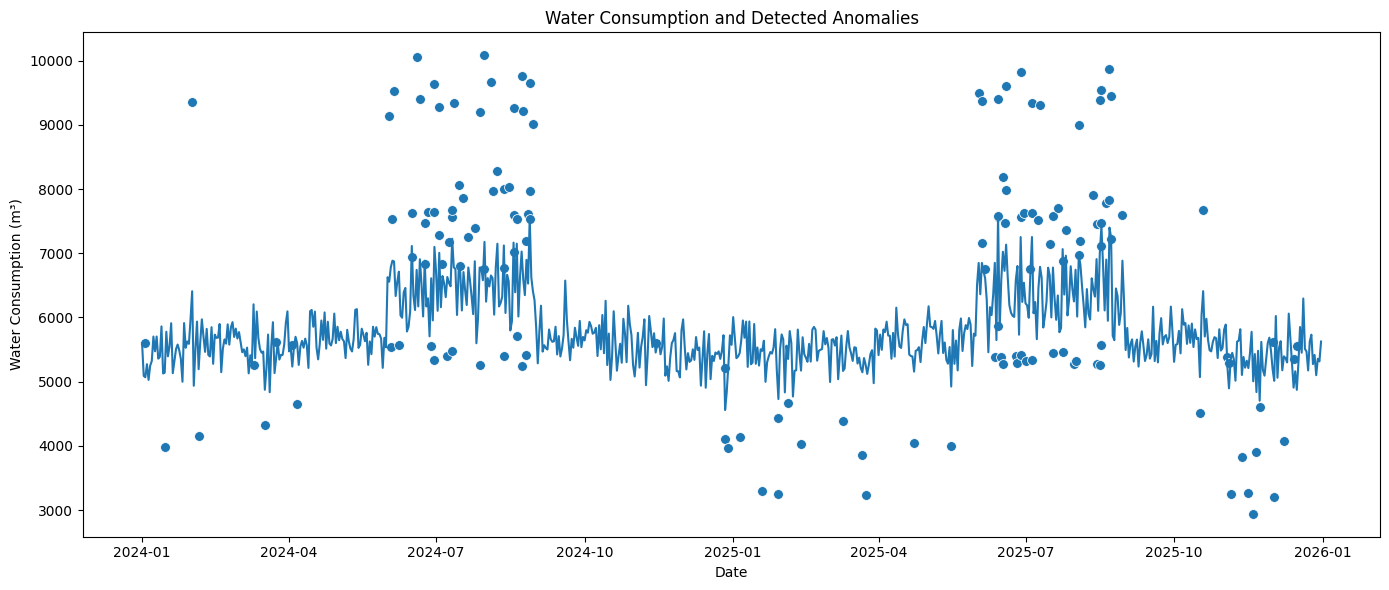

In [35]:
#می‌خواهیم مصرف آب را در طول زمان نمایش دهیم و anomalyها را روی آن مشخص کنیم.
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=df,
    x="Date",
    y="Water_Consumption_m3",
    errorbar=None
)

sns.scatterplot(
    data=zone_anomalies,
    x="Date",
    y="Water_Consumption_m3",
    s=50
)

plt.title("Water Consumption and Detected Anomalies")
plt.xlabel("Date")
plt.ylabel("Water Consumption (m³)")

plt.tight_layout()
plt.show()

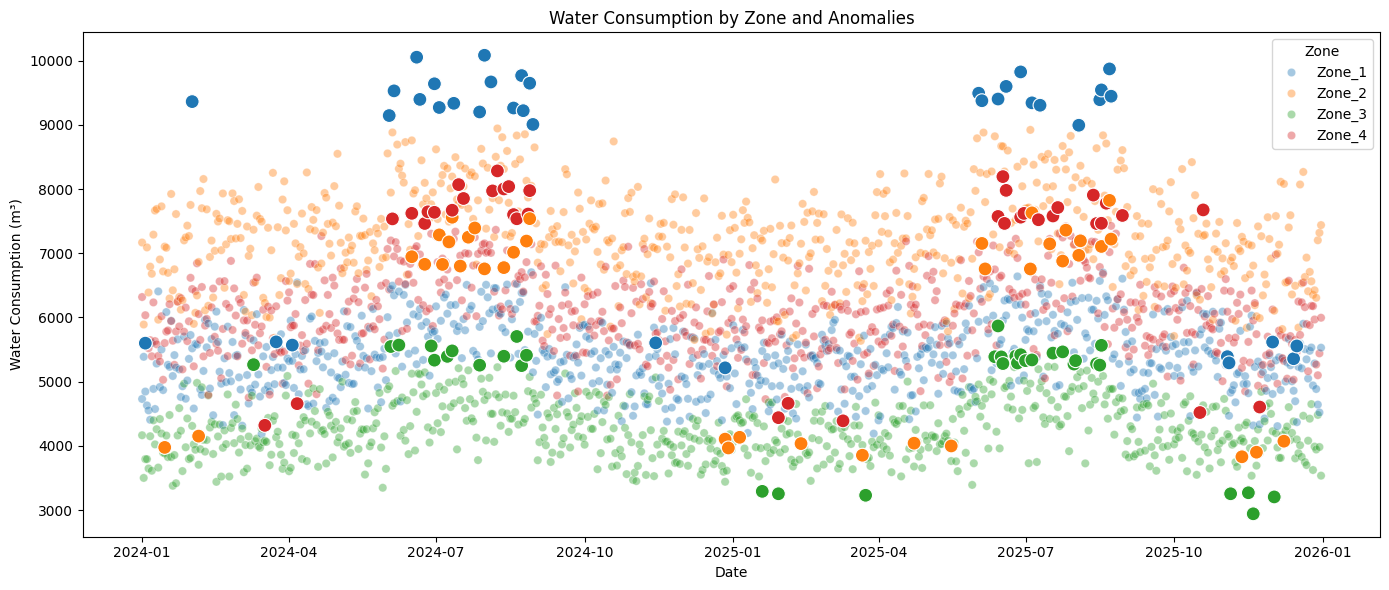

In [36]:
#برای تحلیل دقیق‌تر بهتر است هر منطقه را جداگانه ببینیم.
plt.figure(figsize=(14, 6))

sns.scatterplot(
    data=df,
    x="Date",
    y="Water_Consumption_m3",
    hue="Zone",
    alpha=0.4
)

sns.scatterplot(
    data=zone_anomalies,
    x="Date",
    y="Water_Consumption_m3",
    hue="Zone",
    s=100,
    legend=False
)

plt.title("Water Consumption by Zone and Anomalies")
plt.xlabel("Date")
plt.ylabel("Water Consumption (m³)")

plt.tight_layout()
plt.show()

In [37]:
#1. میانگین مصرف روزانه در هر ماه
#اول مصرف را بر اساس ماه و سال گروه‌بندی می‌کنیم:
monthly_consumption = (
    df.groupby(["Year", "Month"])["Water_Consumption_m3"]
    .mean()
    .reset_index()
)

monthly_consumption

,Year,Month,Water_Consumption_m3
0,2024,1,5453.277258
1,2024,2,5649.923190
2,2024,3,5512.700000
3,2024,4,5658.116000
4,2024,5,5666.075806
5,2024,6,6419.867750
6,2024,7,6527.049597
7,2024,8,6550.742984
8,2024,9,5683.373667
9,2024,10,5665.090484


In [39]:
monthly_consumption["Month_Name"] = (
    pd.to_datetime(
        monthly_consumption["Month"],
        format="%m"
    ).dt.month_name()
)
monthly_consumption

,Year,Month,Water_Consumption_m3,Month_Name
0,2024,1,5453.277258,January
1,2024,2,5649.923190,February
2,2024,3,5512.700000,March
3,2024,4,5658.116000,April
4,2024,5,5666.075806,May
5,2024,6,6419.867750,June
6,2024,7,6527.049597,July
7,2024,8,6550.742984,August
8,2024,9,5683.373667,September
9,2024,10,5665.090484,October


In [40]:
#بیشترین مصرف ماه برای کل دو سال
highest_month = monthly_consumption.loc[
    monthly_consumption["Water_Consumption_m3"].idxmax()
]

print(highest_month)


Year                           2024
Month                             8
Water_Consumption_m3    6550.742984
Month_Name                   August
Name: 7, dtype: object


In [41]:
#کمترین مصرف ماه برای کل دو سال
lowest_month = monthly_consumption.loc[
    monthly_consumption["Water_Consumption_m3"].idxmin()
]

print(lowest_month)


Year                           2025
Month                            11
Water_Consumption_m3    5367.522583
Month_Name                 November
Name: 22, dtype: object


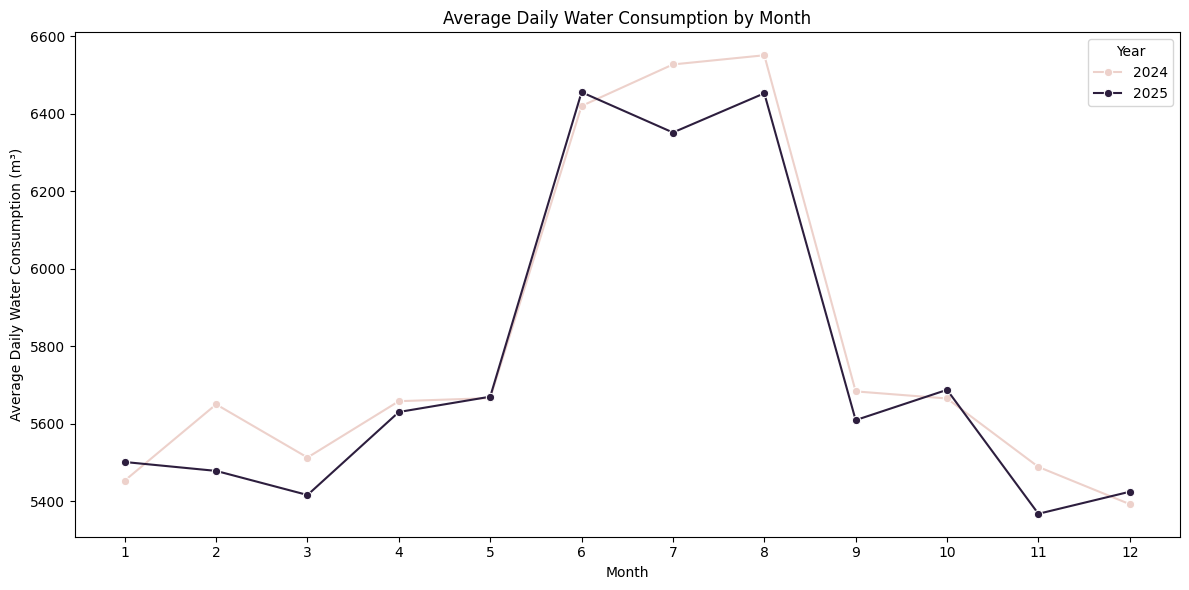

In [43]:
#نمودار مصرف ماهانه
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_consumption,
    x="Month",
    y="Water_Consumption_m3",
    hue="Year",
    marker="o"
)

plt.title("Average Daily Water Consumption by Month")
plt.xlabel("Month")
plt.ylabel("Average Daily Water Consumption (m³)")

plt.xticks(range(1, 13))

plt.tight_layout()
plt.show()


In [44]:
#میانگین مصرف کل هر سال 
yearly_consumption = (
    df.groupby("Year")["Water_Consumption_m3"]
    .mean()
)

print(yearly_consumption)

Year
2024    5806.365178
2025    5755.739637
Name: Water_Consumption_m3, dtype: float64


In [45]:
#محاسبه درصد تغییر
change = (
    (yearly_consumption[2025] - yearly_consumption[2024])
    / yearly_consumption[2024]
) * 100

print(f"Change from 2024 to 2025: {change:.2f}%")


Change from 2024 to 2025: -0.87%


In [46]:
#مصرف هر ماه در ۲۰۲۴ و ۲۰۲۵ را کنار هم قرار می‌دهیم:
year_comparison = monthly_consumption.pivot(
    index="Month",
    columns="Year",
    values="Water_Consumption_m3"
)

year_comparison

Year,2024,2025
Month,,
1,5453.277258,5501.132742
2,5649.923190,5478.221429
3,5512.700000,5416.021048
4,5658.116000,5630.215417
5,5666.075806,5669.703387
6,6419.867750,6455.406250
7,6527.049597,6351.400323
8,6550.742984,6452.588145
9,5683.373667,5609.230667


In [47]:
#برای هر ماه درصد تغییر را محاسبه کنیم:
year_comparison["Change_%"] = (
    (year_comparison[2025] - year_comparison[2024])
    / year_comparison[2024]
) * 100

year_comparison.round(2)


Year,2024,2025,Change_%
Month,,,
1,5453.28,5501.13,0.88
2,5649.92,5478.22,-3.04
3,5512.70,5416.02,-1.75
4,5658.12,5630.22,-0.49
5,5666.08,5669.70,0.06
6,6419.87,6455.41,0.55
7,6527.05,6351.40,-2.69
8,6550.74,6452.59,-1.50
9,5683.37,5609.23,-1.30


In [48]:
#میانگین مصرف روزانه هر منطقه را در هر سال محاسبه می‌کنیم:
zone_yearly = (
    df.groupby(["Year", "Zone"])["Water_Consumption_m3"]
    .mean()
    .reset_index()
)

zone_yearly


,Year,Zone,Water_Consumption_m3
0,2024,Zone_1,5443.703033
1,2024,Zone_2,7356.381721
2,2024,Zone_3,4292.750546
3,2024,Zone_4,6132.625410
4,2025,Zone_1,5428.688027
5,2025,Zone_2,7259.999068
6,2025,Zone_3,4289.952493
7,2025,Zone_4,6044.318959


In [49]:
#آن را به شکل مناسب برای مقایسه درمی‌آوریم
zone_comparison = zone_yearly.pivot(
    index="Zone",
    columns="Year",
    values="Water_Consumption_m3"
)

zone_comparison


Year,2024,2025
Zone,,
Zone_1,5443.703033,5428.688027
Zone_2,7356.381721,7259.999068
Zone_3,4292.750546,4289.952493
Zone_4,6132.625410,6044.318959


In [50]:
#درصد رشد
zone_comparison["Growth_%"] = (
    (zone_comparison[2025] - zone_comparison[2024])
    / zone_comparison[2024]
) * 100

zone_comparison.round(2)


Year,2024,2025,Growth_%
Zone,,,
Zone_1,5443.70,5428.69,-0.28
Zone_2,7356.38,7260.00,-1.31
Zone_3,4292.75,4289.95,-0.07
Zone_4,6132.63,6044.32,-1.44


In [51]:
#منطقه‌ای که بیشترین رشد را داشته:
highest_growth_zone = zone_comparison["Growth_%"].idxmax()

highest_growth = zone_comparison.loc[
    highest_growth_zone,
    "Growth_%"
]

print(
    f"{highest_growth_zone} had the highest growth "
    f"with {highest_growth:.2f}%."
)


Zone_3 had the highest growth with -0.07%.


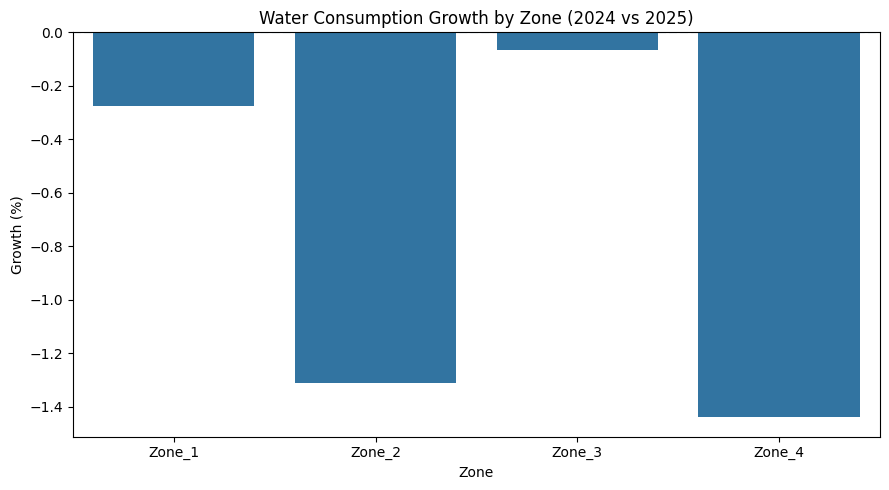

In [52]:
#نمودار رشد مناطق
plt.figure(figsize=(9, 5))

sns.barplot(
    data=zone_comparison.reset_index(),
    x="Zone",
    y="Growth_%"
)

plt.title("Water Consumption Growth by Zone (2024 vs 2025)")
plt.xlabel("Zone")
plt.ylabel("Growth (%)")

plt.axhline(0, linestyle="--")

plt.tight_layout()
plt.show()


In [53]:
print(highest_month)
print(lowest_month)

Year                           2024
Month                             8
Water_Consumption_m3    6550.742984
Month_Name                   August
Name: 7, dtype: object
Year                           2025
Month                            11
Water_Consumption_m3    5367.522583
Month_Name                 November
Name: 22, dtype: object


In [54]:
print(yearly_consumption)
print(f"Change: {change:.2f}%")

Year
2024    5806.365178
2025    5755.739637
Name: Water_Consumption_m3, dtype: float64
Change: -0.87%


In [55]:
print(
    f"{highest_growth_zone}: "
    f"{highest_growth:.2f}%"
)

Zone_3: -0.07%


In [56]:
year_comparison.round(2)

Year,2024,2025,Change_%
Month,,,
1,5453.28,5501.13,0.88
2,5649.92,5478.22,-3.04
3,5512.70,5416.02,-1.75
4,5658.12,5630.22,-0.49
5,5666.08,5669.70,0.06
6,6419.87,6455.41,0.55
7,6527.05,6351.40,-2.69
8,6550.74,6452.59,-1.50
9,5683.37,5609.23,-1.30


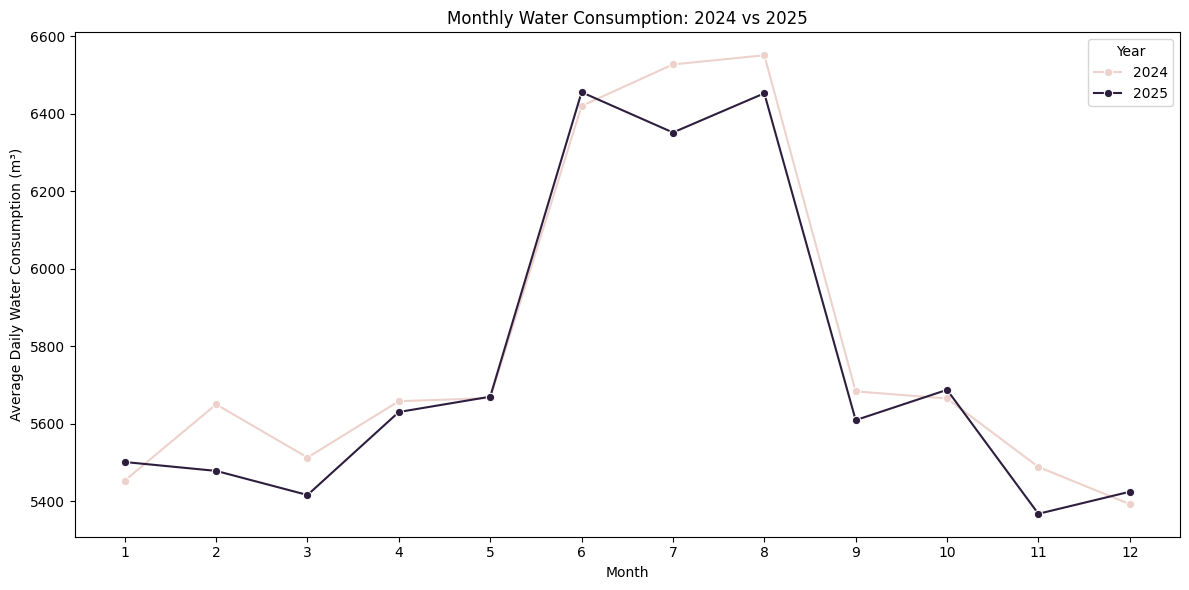

In [57]:
#2024 vs 2025 Monthly Consumption
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_consumption,
    x="Month",
    y="Water_Consumption_m3",
    hue="Year",
    marker="o"
)

plt.title("Monthly Water Consumption: 2024 vs 2025")
plt.xlabel("Month")
plt.ylabel("Average Daily Water Consumption (m³)")
plt.xticks(range(1, 13))

plt.tight_layout()
plt.show()


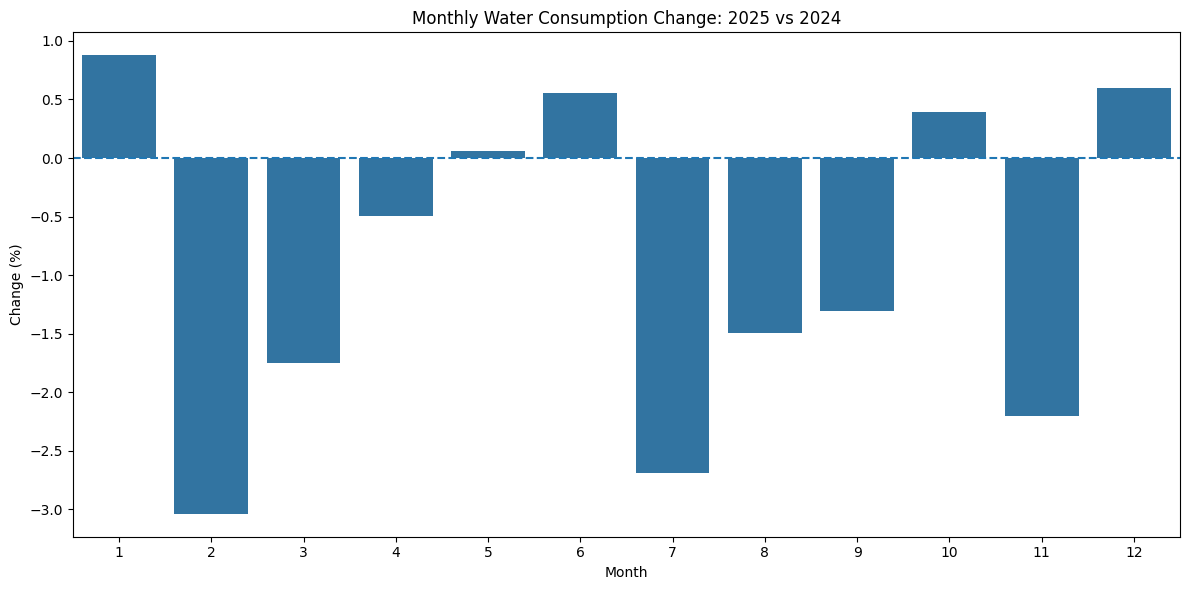

In [58]:
#یک نمودار دوم:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=year_comparison.reset_index(),
    x="Month",
    y="Change_%",
)

plt.axhline(0, linestyle="--")

plt.title("Monthly Water Consumption Change: 2025 vs 2024")
plt.xlabel("Month")
plt.ylabel("Change (%)")

plt.tight_layout()
plt.show()